# 🔎📚 Lab 04: RAG Evaluation Pipeline

## Module 04 — Evaluating Retrieval-Augmented Systems 📚

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/04-rag-evaluation-lab.ipynb)

| | |
|---|---|
| ⏱️ **Time** | 25–30 min hands-on |
| 🎚️ **Level** | Intermediate |
| 🔑 **Accounts / keys** | None. One ~90 MB NLI model downloads on first run |
| 🧰 **You'll use** | `sentence-transformers` (NLI cross-encoder) · `pandas` · `numpy` |
| ✍️ **You'll write** | Grounding criteria (Task 5), stress tests (Task 7), divergence analysis (Task 9) |
| 🏁 **You'll leave with** | Retrieval + faithfulness scores and a root cause for every query |
| ➡️ **Next** | Lab 04b builds a *real* RAG pipeline on a vector DB and evaluates it |

---

## 🧭 Overview

In this lab, you will evaluate a **Retrieval-Augmented Generation (RAG)** system that answers questions about company policies. You will work through the full RAG evaluation pipeline: measuring retrieval quality, assessing whether generated answers are grounded in retrieved documents, scoring faithfulness, designing stress tests, and tracing failures back to their root cause.

## 🏗️ What You'll Build

By the end of this lab you will have:
- 📊 Loaded and explored a RAG evaluation dataset
- 📏 Computed retrieval metrics (Recall@K, Precision@K, nDCG)
- 📝 Designed grounding evaluation criteria
- 🧪 Implemented faithfulness scoring using NLI-based and rule-based methods
- 💥 Created stress test queries for RAG system weaknesses
- 🔍 Analyzed traced RAG examples to identify failure root causes
- ⚖️ Investigated cases where retrieval and generation quality diverge

## 🗺️ The RAG Evaluation Pipeline

Here's the RAG pipeline you'll be evaluating — and *where* each evaluation technique applies:

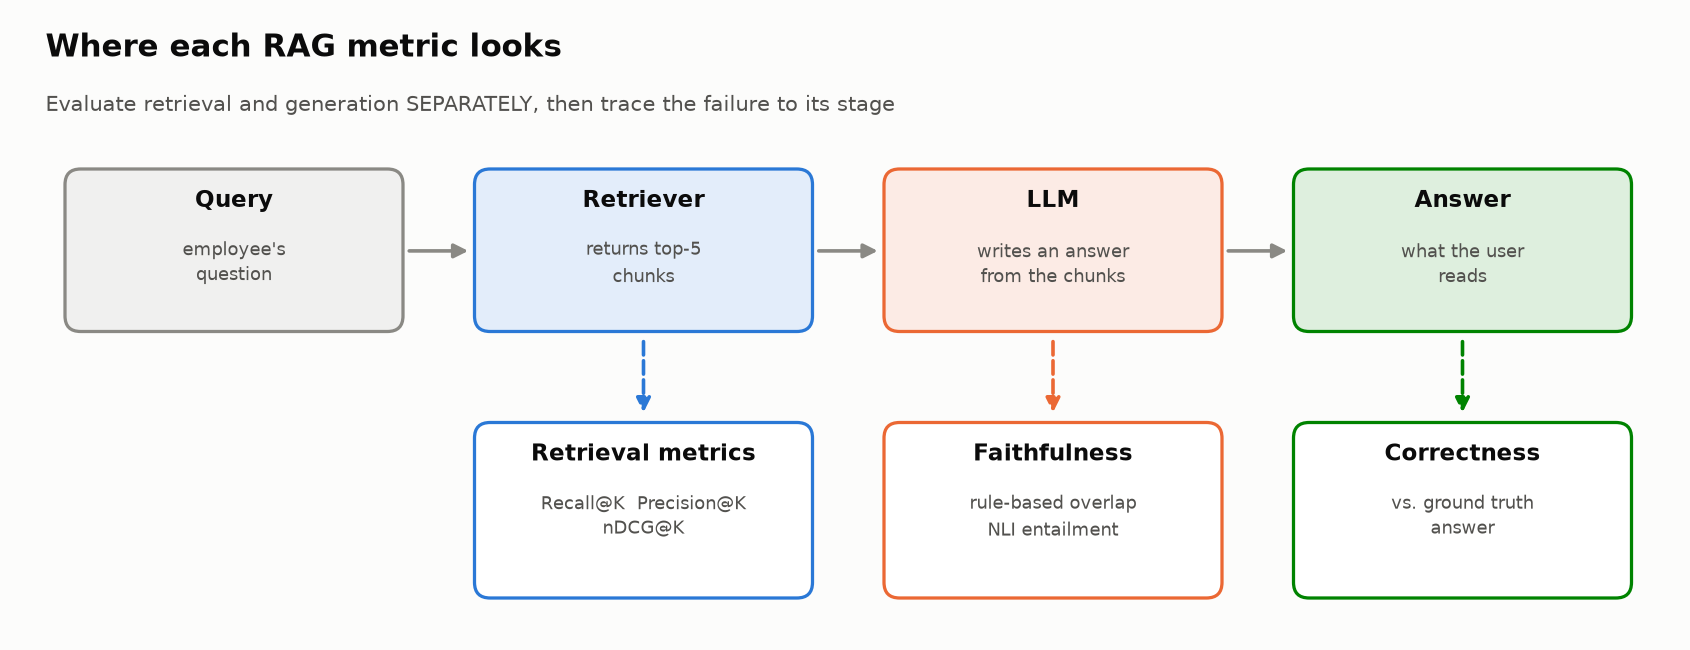

<sub>🖼️ *Where each evaluation technique in this lab plugs into the RAG pipeline*</sub>

> 💡 **Key Insight:** A RAG system can fail at **retrieval** OR **generation** — you need to evaluate both stages independently to know where to fix problems.

## 🎯 Learning Objectives

1. Compute and interpret retrieval metrics (Recall@K, Precision@K, nDCG)
2. Evaluate grounding and attribution in generated responses
3. Assess faithfulness using entailment-based methods
4. Design stress tests for ambiguous, adversarial, and out-of-scope queries
5. Trace RAG execution paths to identify failure root causes

## 📋 Prerequisites

- Module 01 (Modern AI Evaluation Foundations) completed
- Module 02 (Failure Mode Analysis) completed
- Basic understanding of RAG architecture (query → retrieval → generation)
- Python proficiency (pandas, numpy)

## ⏱️ Estimated Time

**25–30 minutes** hands-on

## 🎬 Scenario

You are an ML engineer evaluating a RAG-based Q&A system used by employees to look up company policies (PTO, expenses, remote work, etc.). The system retrieves relevant policy documents and generates answers. Management has noticed some answers that "sound right but aren't" — and others where the system clearly retrieves the wrong documents but still produces a plausible-sounding response.

Your job: build an evaluation pipeline that separately measures **retrieval quality** and **generation quality**, find where they diverge, and design tests that stress the system's weaknesses.

> ⚠️ **Common Mistake:** High-quality retrieval doesn't guarantee high-quality answers — and vice versa. An answer can sound perfect while being completely fabricated.

---

## 🛠️ Task 1: Environment Setup and Dependencies

### Goal
Install and import the required packages for retrieval metrics, faithfulness scoring, and data analysis.

### Why This Step?
We need `sentence-transformers` for the NLI (Natural Language Inference) cross-encoder model that will power our semantic faithfulness scoring later. The other packages (`scikit-learn`, `pandas`, `numpy`) provide standard data manipulation and numerical tools.

### Steps
Run the cells below to install dependencies and import libraries. This may take 1–2 minutes.

In [ ]:
%%capture
# Install required packages:
#   sentence-transformers → provides the NLI cross-encoder for faithfulness scoring (Task 6)
#   scikit-learn          → general ML utilities
#   pandas / numpy        → data manipulation and numerical operations
!pip install sentence-transformers scikit-learn pandas numpy

In [ ]:
# Core libraries for data handling and analysis
import pandas as pd           # DataFrames for tabular metric summaries
import numpy as np            # Numerical ops — used in nDCG log calculations
import json                   # JSON handling (if loading external datasets)
from collections import defaultdict  # For grouping trace results by root cause

print("✅ All imports successful.")

### Checkpoint ✅
You should see `✅ All imports successful.` with no errors. If you see a `ModuleNotFoundError`, re-run the install cell and restart the kernel.

---

## 📂 Task 2: Load the RAG Evaluation Dataset

### Goal
Load a synthetic RAG evaluation dataset representing a company policy Q&A system. Each entry contains a query, the top-5 retrieved documents (with relevance labels), and the generated answer.

### 🎯 Why This Matters
Before we can evaluate a RAG system, we need to understand what **data flows through each stage**. Every entry in this dataset captures one complete trip through the pipeline:

```
  User Question → [Retriever finds 5 docs] → [LLM generates answer] → Response
                        ↑                           ↑
                  relevance_labels             generated_answer
                 (did we find the             (is it faithful to
                  right docs?)                 what was found?)
```

By including **relevance labels** (which docs are actually relevant) and **ground truth** (the correct answer), we can measure failures at *each* stage independently.

### Dataset Schema
- **query**: Employee's question about company policy
- **retrieved_docs**: List of 5 retrieved document chunks (ranked by retrieval score)
- **relevance_labels**: Binary list — 1 if the doc is relevant to the query, 0 if not
- **generated_answer**: The RAG system's generated response
- **ground_truth**: The correct answer from the policy handbook
- **has_relevant_retrieval**: Whether at least one relevant doc was retrieved

### Steps
Run the cell below to create the synthetic dataset.

In [ ]:
# Synthetic RAG evaluation dataset — company policy Q&A system
# Each entry represents one COMPLETE query through the RAG pipeline:
#   query → retriever returns 5 docs → LLM generates answer
#
# Key fields to watch:
#   - relevance_labels: [1,0,0,0,0] means only the 1st doc is relevant
#   - Some queries have 0 relevant docs (retrieval failure!)
#   - Some generated answers contain fabricated information (generation failure!)

rag_dataset = [
    {
        "id": 1,
        "query": "How many PTO days do new employees get?",
        "retrieved_docs": [
            "New full-time employees receive 15 PTO days per year, accrued monthly starting from their hire date.",
            "PTO requests must be submitted at least 2 weeks in advance through the HR portal.",
            "After 5 years of service, employees receive an additional 5 PTO days per year.",
            "Company holidays include New Year's Day, Memorial Day, Independence Day, Labor Day, Thanksgiving, and Christmas.",
            "Part-time employees receive prorated PTO based on their scheduled hours."
        ],
        "relevance_labels": [1, 0, 0, 0, 0],  # Only doc 1 directly answers the question
        "generated_answer": "New full-time employees receive 15 PTO days per year, which accrue monthly starting from their hire date.",
        "ground_truth": "New full-time employees receive 15 PTO days per year, accrued monthly from hire date."
    },
    {
        "id": 2,
        "query": "What is the expense reimbursement limit for client dinners?",
        "retrieved_docs": [
            "Travel expenses must be submitted within 30 days of the trip using the expense management system.",
            "Office supply purchases under $50 do not require pre-approval.",
            "Client entertainment expenses are capped at $150 per person per meal and require a receipt and attendee list.",
            "Employees may expense co-working space fees up to $200/month when traveling.",
            "Annual team-building budgets are allocated at $500 per team member."
        ],
        "relevance_labels": [0, 0, 1, 0, 0],  # Relevant doc is at position 3 (not ideal ranking)
        "generated_answer": "Client dinner expenses are capped at $150 per person per meal. You'll need to submit a receipt and a list of attendees.",
        "ground_truth": "Client entertainment expenses are capped at $150 per person per meal, requiring a receipt and attendee list."
    },
    {
        "id": 3,
        "query": "Can I work remotely from another country?",
        "retrieved_docs": [
            "Remote work is available for all full-time employees with manager approval.",
            "Employees working remotely must maintain core hours of 10am-3pm in their local time zone.",
            "International remote work requires approval from both your manager and the Legal department due to tax and compliance implications. Requests must be submitted 30 days in advance.",
            "Home office equipment stipends of up to $1,000 are available for new remote workers.",
            "VPN access is required for all remote work to ensure secure connections to company systems."
        ],
        "relevance_labels": [0, 0, 1, 0, 0],  # Relevant doc buried at position 3
        "generated_answer": "Yes, you can work remotely from another country, but it requires approval from your manager and the Legal department. You need to submit the request 30 days in advance due to tax and compliance considerations.",
        "ground_truth": "International remote work requires manager and Legal approval, submitted 30 days in advance, due to tax and compliance implications."
    },
    {
        "id": 4,
        "query": "What happens if I exceed my PTO balance?",
        # ⚠️ RETRIEVAL FAILURE: None of these 5 docs are relevant to the question!
        "retrieved_docs": [
            "Company holidays include New Year's Day, Memorial Day, Independence Day, Labor Day, Thanksgiving, and Christmas.",
            "The employee assistance program provides free counseling sessions for stress management.",
            "Parking passes are available at a subsidized rate of $50/month in the company garage.",
            "The cafeteria offers a meal plan at $8/day for employees.",
            "Gym membership reimbursements are available up to $75/month."
        ],
        "relevance_labels": [0, 0, 0, 0, 0],  # ZERO relevant docs — complete retrieval failure
        "generated_answer": "If you exceed your PTO balance, additional days off will be unpaid. You should discuss extended leave options with HR, who can help you explore short-term disability or unpaid leave of absence.",
        "ground_truth": "Days taken beyond the PTO balance are unpaid. Employees must get manager approval for unpaid leave, and HR should be notified for payroll adjustment."
    },
    {
        "id": 5,
        "query": "How does the 401k match work?",
        "retrieved_docs": [
            "The company matches 401(k) contributions dollar-for-dollar up to 4% of base salary. Matching contributions vest over 3 years: 33% after year 1, 66% after year 2, 100% after year 3.",
            "Health insurance enrollment occurs during the annual open enrollment period in November.",
            "Employees can adjust their 401(k) contribution percentage at any time through the benefits portal.",
            "The company offers both traditional and Roth 401(k) options.",
            "Financial planning consultations are available quarterly at no cost to employees."
        ],
        "relevance_labels": [1, 0, 1, 1, 0],  # 3 relevant docs — strong retrieval
        "generated_answer": "The company provides a dollar-for-dollar 401(k) match up to 4% of your base salary. The match vests over 3 years at 33%, 66%, and 100%. You can choose between traditional and Roth 401(k) options and adjust contributions anytime via the benefits portal.",
        "ground_truth": "Dollar-for-dollar match up to 4% of base salary. 3-year vesting schedule (33/66/100%). Both traditional and Roth options available."
    },
    {
        "id": 6,
        "query": "What is the policy on bringing pets to the office?",
        # ⚠️ RETRIEVAL FAILURE + HALLUCINATION: No relevant docs, but the answer sounds confident!
        "retrieved_docs": [
            "The dress code is business casual Monday through Thursday and casual on Fridays.",
            "Visitors must sign in at the front desk and wear a visitor badge at all times.",
            "Food delivery orders should be picked up at the main lobby reception area.",
            "Conference rooms must be booked through the scheduling system at least 1 hour in advance.",
            "The building is non-smoking. Designated smoking areas are located in the parking structure."
        ],
        "relevance_labels": [0, 0, 0, 0, 0],  # ZERO relevant docs — another complete retrieval failure
        "generated_answer": "Pets are welcome in the office on designated Pet-Friendly Fridays. Dogs must be leashed in common areas and owners are responsible for cleanup. Please notify your floor manager in advance.",
        "ground_truth": "The company does not currently have a pet policy. Pets are not permitted in the office unless they are registered service animals."
    },
    {
        "id": 7,
        "query": "How do I report a workplace safety concern?",
        "retrieved_docs": [
            "Workplace safety concerns should be reported immediately to your manager or the Safety Committee via the anonymous reporting hotline at ext. 2222 or through the online safety portal.",
            "All employees must complete annual safety training by December 31st.",
            "Fire extinguishers are located at each stairwell entrance and in the kitchen areas.",
            "First aid kits are available in each break room and at the front desk.",
            "Emergency evacuation routes are posted by each elevator and stairwell."
        ],
        "relevance_labels": [1, 0, 0, 0, 0],  # Only doc 1 is relevant
        "generated_answer": "You can report safety concerns to your manager or use the anonymous Safety Committee hotline at extension 2222. There's also an online safety portal available for reporting.",
        "ground_truth": "Report to manager or Safety Committee via anonymous hotline (ext. 2222) or online safety portal."
    },
    {
        "id": 8,
        "query": "What are the rules for using company credit cards?",
        # ✅ PERFECT RETRIEVAL: All 5 docs are relevant!
        "retrieved_docs": [
            "Company credit cards are issued to employees at the director level and above. All charges must have a business justification and receipt.",
            "Personal charges on company credit cards are strictly prohibited and may result in disciplinary action.",
            "Monthly credit card statements must be reconciled and approved by the cardholder's manager within 15 business days.",
            "Lost or stolen company credit cards must be reported to Finance and the card issuer within 24 hours.",
            "Credit card limits are set based on role: Directors $5,000, VPs $10,000, C-suite $25,000."
        ],
        "relevance_labels": [1, 1, 1, 1, 1],  # ALL 5 docs relevant — best-case retrieval
        "generated_answer": "Company credit cards are available for directors and above. All charges need a business justification and receipt. Personal use is prohibited. Monthly statements must be reconciled within 15 business days with manager approval. Report lost cards to Finance within 24 hours.",
        "ground_truth": "Issued to directors+. Business justification and receipts required. No personal use. Monthly reconciliation within 15 business days. Report lost/stolen within 24 hours."
    },
    {
        "id": 9,
        "query": "Can I use my education stipend for an online bootcamp?",
        "retrieved_docs": [
            "The annual education stipend of $3,000 covers tuition, books, and course materials for job-related education. Eligible programs include accredited degrees, professional certifications, and approved online courses.",
            "Employees must receive manager approval before enrolling and submit receipts for reimbursement within 60 days of course completion.",
            "The mentorship program pairs junior employees with senior leaders for quarterly development conversations.",
            "Internal lunch-and-learn sessions are held every other Friday and count toward professional development hours.",
            "Conference attendance requires VP-level approval and is budgeted separately from the education stipend."
        ],
        "relevance_labels": [1, 1, 0, 0, 0],  # 2 relevant docs
        "generated_answer": "Yes, online bootcamps can be covered under the $3,000 annual education stipend as long as they are job-related. You'll need manager approval before enrolling. After completing the program, submit your receipts within 60 days for reimbursement.",
        "ground_truth": "The $3,000 education stipend covers job-related education including approved online courses. Manager approval required before enrollment, receipts due within 60 days."
    },
    {
        "id": 10,
        "query": "What is the parental leave policy?",
        # ⚠️ GENERATION FAILURE: Retrieval is great, but the answer changes "12 weeks" to "16 weeks"!
        "retrieved_docs": [
            "Full-time employees are eligible for 12 weeks of paid parental leave for the birth, adoption, or foster placement of a child. Leave must begin within 12 months of the qualifying event.",
            "Parental leave can be taken consecutively or split into two blocks with manager approval.",
            "During parental leave, all benefits including health insurance and 401(k) matching continue.",
            "Employees returning from parental leave are guaranteed the same or equivalent position.",
            "Short-term disability insurance covers 60% of salary for up to 26 weeks for medical conditions including pregnancy complications."
        ],
        "relevance_labels": [1, 1, 1, 1, 0],  # 4/5 relevant — very strong retrieval
        "generated_answer": "The company offers 16 weeks of fully paid parental leave for all new parents. You can take it all at once or split it into blocks. Your health insurance and retirement benefits continue during leave.",
        "ground_truth": "12 weeks paid parental leave for birth, adoption, or foster placement. Can be consecutive or split into two blocks. Benefits continue. Same/equivalent position guaranteed on return."
    },
    {
        "id": 11,
        "query": "How do I request a standing desk?",
        "retrieved_docs": [
            "Ergonomic equipment requests including standing desks, monitor arms, and keyboard trays can be submitted through the Facilities portal. Standard processing time is 5-7 business days.",
            "All new employees receive a standard desk setup including a monitor, keyboard, and mouse.",
            "The IT help desk handles requests for additional monitors, docking stations, and peripherals.",
            "Office furniture changes require approval from your floor coordinator to ensure space planning compliance.",
            "Height-adjustable desks are available in two models: manual crank ($400) and electric ($650). Both are covered by the company."
        ],
        "relevance_labels": [1, 0, 0, 1, 1],  # 3 relevant docs
        "generated_answer": "Submit a request through the Facilities portal for a standing desk. Processing takes 5-7 business days. You'll need your floor coordinator's approval. The company covers the cost — choose between a manual crank model or an electric one.",
        "ground_truth": "Request via Facilities portal (5-7 business days). Floor coordinator approval needed. Two models available: manual ($400) and electric ($650), both company-covered."
    },
    {
        "id": 12,
        "query": "What happens to my unvested stock options if I leave?",
        "retrieved_docs": [
            "Stock options vest over a 4-year schedule with a 1-year cliff. After the cliff, options vest monthly.",
            "Upon voluntary termination, employees have 90 days to exercise vested stock options. Unvested options are forfeited.",
            "In the event of involuntary termination without cause, the company may accelerate vesting at its discretion.",
            "Stock option grants are determined annually based on performance review and level.",
            "Tax implications of stock option exercise should be discussed with a personal financial advisor. The company provides access to a tax consultation service."
        ],
        "relevance_labels": [1, 1, 1, 0, 0],  # 3 relevant docs
        "generated_answer": "If you leave the company, your unvested stock options are forfeited. You have 90 days after departure to exercise any vested options. If you were terminated without cause, the company may choose to accelerate vesting, though this is discretionary.",
        "ground_truth": "Unvested options are forfeited on departure. 90 days to exercise vested options. Involuntary termination without cause may trigger discretionary accelerated vesting."
    },
]

# Display dataset summary — note how retrieval quality varies across queries
print(f"Loaded {len(rag_dataset)} RAG evaluation examples.\n")

for item in rag_dataset:
    n_relevant = sum(item["relevance_labels"])
    # Flag extreme cases to draw attention
    flag = "⚠️" if n_relevant == 0 else ("🟢" if n_relevant >= 3 else "  ")
    print(f"  {flag} Query {item['id']:2d}: \"{item['query'][:60]}...\"  "
          f"[{n_relevant}/5 relevant docs]")

In [ ]:
# Convert to DataFrame for a quick statistical overview of the dataset
# This helps us spot patterns BEFORE diving into per-query evaluation
df = pd.DataFrame([{
    "id": item["id"],
    "query": item["query"],
    "n_relevant": sum(item["relevance_labels"]),     # How many of the 5 retrieved docs are relevant?
    "n_retrieved": len(item["retrieved_docs"]),       # Always 5 in our dataset (top-5 retrieval)
    "answer_length": len(item["generated_answer"]),   # Longer answers = more opportunities for errors
    "has_relevant": sum(item["relevance_labels"]) > 0,  # Did retrieval find ANY relevant doc?
} for item in rag_dataset])

print("Dataset Summary:")
print(f"  Total queries: {len(df)}")
print(f"  Queries with ≥1 relevant doc: {df['has_relevant'].sum()}")
print(f"  Queries with 0 relevant docs: {(~df['has_relevant']).sum()}")
print(f"  Avg relevant docs per query: {df['n_relevant'].mean():.1f}")
print()
df

### Checkpoint ✅
You should see `Loaded 12 RAG evaluation examples.` followed by a summary showing:
- 12 total queries
- Some queries with 0 relevant docs (retrieval failures)
- Variable numbers of relevant docs per query

### Expected Output
```
Loaded 12 RAG evaluation examples.

  Query  1: "How many PTO days do new employees get?..."  [1/5 relevant docs]
  Query  2: "What is the expense reimbursement limit for client din..."  [1/5 relevant docs]
  ...
```

Notice the variation: some queries have many relevant docs retrieved (queries 5, 8, 12), while others have zero (queries 4, 6). This variation is intentional — it lets us test how retrieval quality affects generation quality.

### 🔍 What Just Happened?

You loaded 12 RAG examples — each one a complete trip through the pipeline. Crucially, you can already see that retrieval quality **varies wildly**:
- Some queries got 0 relevant docs (complete retrieval failure)
- Others got all 5 relevant (perfect retrieval)

This variation is what makes RAG evaluation interesting — and why we can't just check if the final answer is "correct." We need to understand *where* things went wrong.

> 🎯 **Why This Matters:** If you only measured final answer quality, you'd miss the root cause. A wrong answer from bad retrieval needs a different fix than a wrong answer from bad generation.

Now let's move to the **thinking** stage — before we compute any metrics, we'll reason about what "trustworthy" even means for a RAG system.

---

## Task 3: 🔍 Think First — What Makes a RAG Response Trustworthy?

### Goal
Before computing any metrics, pause and reason about what makes a RAG response **trustworthy** vs **problematic**. This shapes every evaluation decision you'll make in this lab.

### Context
Look at these two responses from our dataset:

**Query 4:** "What happens if I exceed my PTO balance?"
> **Generated answer:** "If you exceed your PTO balance, additional days off will be unpaid. You should discuss extended leave options with HR, who can help you explore short-term disability or unpaid leave of absence."

**Query 6:** "What is the policy on bringing pets to the office?"
> **Generated answer:** "Pets are welcome in the office on designated Pet-Friendly Fridays. Dogs must be leashed in common areas and owners are responsible for cleanup."

Both responses sound confident and professional. But one of them is completely fabricated — the system retrieved **zero relevant documents** for both queries, yet still produced fluent answers.

### Questions to Reason About

Spend **3–4 minutes** thinking about these questions. Write your answers in the cell below.

1. **Trustworthiness signals:** What observable properties of a RAG response would make you trust it? Think about the relationship between the retrieved documents and the generated answer.

2. **Danger signals:** What characteristics would make you *distrust* a RAG response, even if it sounds fluent and confident?

3. **Retrieval vs Generation:** Can a RAG system retrieve perfect documents but still generate a bad answer? Can it retrieve irrelevant documents but still produce a good answer? What does each scenario tell you?

4. **Evaluation priority:** If you could only measure ONE thing about a RAG system, what would it be and why?

> **This is a challenge section.** There are no answers provided. Form your own reasoning — we'll use your thinking to guide the rest of the lab.

### ✍️ Your Reflections

**Write your answers here** (double-click to edit this cell):

1. **Trustworthiness signals:**

   *Your answer...*

2. **Danger signals:**

   *Your answer...*

3. **Retrieval vs Generation:**

   *Your answer...*

4. **Evaluation priority:**

   *Your answer...*

---
*Keep this cell — your reasoning here will inform how you approach the metrics and challenges below.*

---

## Task 4: 📏 Compute Retrieval Metrics (Recall@K, Precision@K, nDCG)

Now that you've thought about what makes a RAG response trustworthy, let's **quantify** retrieval quality with three standard metrics. These answer the first question in RAG evaluation: *Did the retriever find the right documents?*

### Goal
Implement and compute the three core retrieval metrics to measure how well the retrieval component finds relevant documents.

### 🎯 Why Evaluate Retrieval Separately?
The retriever is the *foundation* of a RAG system. If it serves the wrong documents to the LLM, even the best generator will struggle. Think of it like cooking: retrieval picks the ingredients, generation is the recipe. Bad ingredients → bad dish, no matter how good the chef.

```
  Which metric answers which question?
  ─────────────────────────────────────────────────────────
  Recall@K      → "Did we FIND the right documents?"
  Precision@K   → "How much NOISE is in our results?"
  nDCG          → "Are the best docs RANKED near the top?"
  ─────────────────────────────────────────────────────────
```

### Background
- **Recall@K**: Of all relevant documents that *exist*, what fraction did we retrieve in the top K? (Did we *find* the right documents?)
- **Precision@K**: Of the K documents we retrieved, what fraction are relevant? (How much noise is in our results?)
- **nDCG (Normalized Discounted Cumulative Gain)**: Are the relevant documents ranked *near the top*? (Penalizes relevant docs buried at rank 4 or 5)

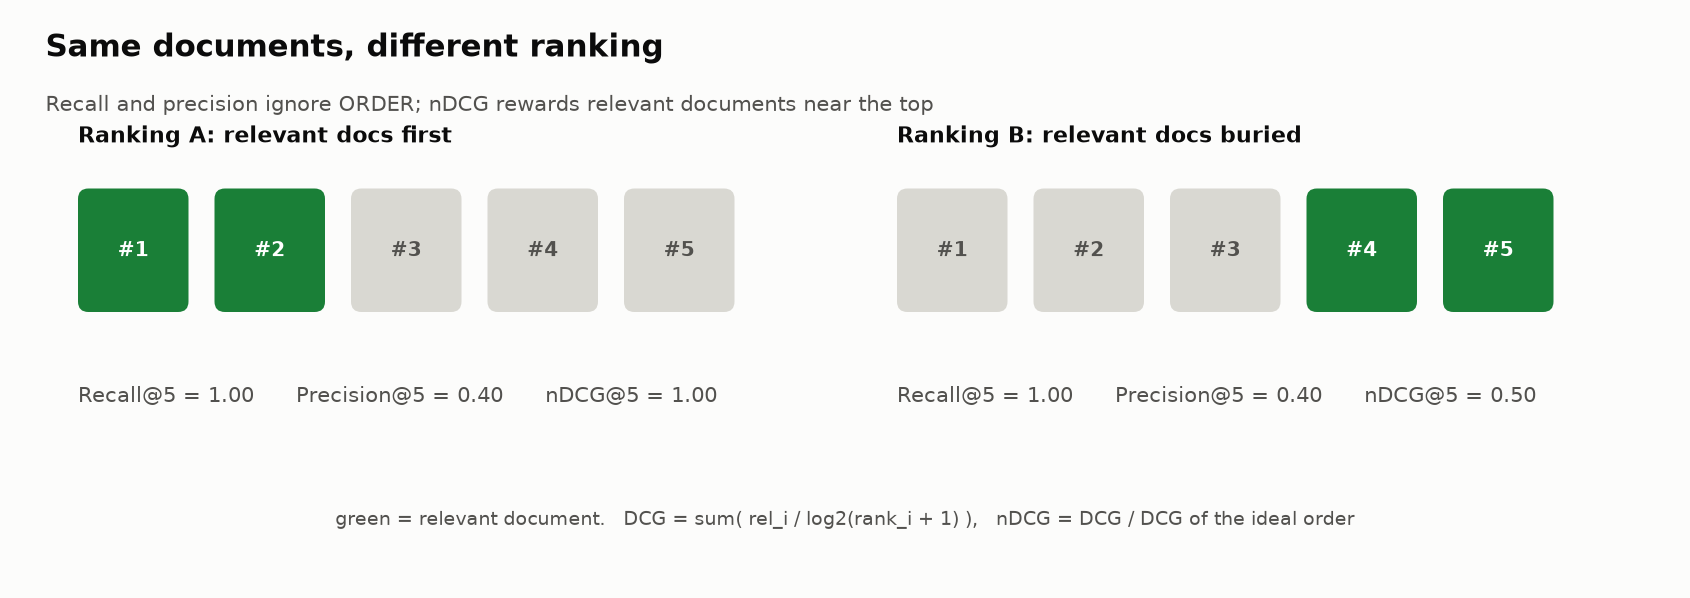

<sub>🖼️ *Same two relevant documents, different positions: only nDCG notices*</sub>

> ⚠️ **Read this before you interpret Recall@5.** Our labels only cover the 5 documents the retriever returned; we don't know how many relevant documents exist in the *whole* corpus. So here Recall@5 means "of the relevant docs **in the retrieved pool**, how many are in the top 5?", and with K = 5 = pool size it is always 0 or 1. True recall needs labels for the corpus, which you'll have in **Lab 04b** (`relevant_doc_ids`).

> 💡 **Key Insight:** These three metrics capture different failure modes. A system could have high recall (found the docs) but low nDCG (buried them at the bottom of the list).

### Steps
1. Implement the three metric functions
2. Compute metrics for each query
3. Analyze which queries have the best/worst retrieval

In [ ]:
def recall_at_k(relevance_labels, k=5):
    """
    Recall@K: proportion of relevant documents retrieved out of total relevant.
    If there are no relevant documents at all, return 0.

    Example: If 3 relevant docs exist and we retrieved 2 of them in top-5,
    Recall@5 = 2/3 = 0.667
    """
    labels_at_k = relevance_labels[:k]       # Only look at top-K results
    total_relevant = sum(relevance_labels)    # How many relevant docs exist in the pool?
    if total_relevant == 0:
        return 0.0  # Can't recall anything if nothing is relevant
    return sum(labels_at_k) / total_relevant  # Fraction found out of total


def precision_at_k(relevance_labels, k=5):
    """
    Precision@K: proportion of retrieved documents (top K) that are relevant.
    Measures how "clean" the retrieval results are.

    Example: If 2 out of 5 retrieved docs are relevant,
    Precision@5 = 2/5 = 0.4
    """
    labels_at_k = relevance_labels[:k]  # Only look at top-K results
    return sum(labels_at_k) / k         # Fraction of results that are relevant


def ndcg_at_k(relevance_labels, k=5):
    """
    nDCG@K: Normalized Discounted Cumulative Gain.
    Measures ranking quality — relevant docs at higher ranks score more.
    A relevant doc at position 1 contributes more than one at position 5.

    The "discounting" means: score = relevance / log2(rank + 1)
    So rank 1 gets full credit, rank 2 gets ~63%, rank 3 gets ~50%, etc.
    We normalize by the IDEAL ranking (all relevant docs first) to get 0–1 scale.
    """
    labels_at_k = relevance_labels[:k]

    # DCG: sum of relevance / log2(rank + 1)
    # The +2 is because enumerate starts at 0, and log2 denominator starts at rank 2
    dcg = sum(rel / np.log2(i + 2) for i, rel in enumerate(labels_at_k))

    # Ideal DCG: what if we had the PERFECT ranking? (all relevant docs first)
    ideal_labels = sorted(relevance_labels, reverse=True)[:k]
    idcg = sum(rel / np.log2(i + 2) for i, rel in enumerate(ideal_labels))

    if idcg == 0:
        return 0.0  # No relevant docs → nDCG undefined, return 0
    return dcg / idcg  # Ratio of actual vs ideal ranking quality


# ── Verification: test on a simple example to make sure the math works ──
test_labels = [0, 1, 0, 1, 0]  # Relevant docs at positions 2 and 4 (not ideal)
print("Verification with test labels [0, 1, 0, 1, 0]:")
print(f"  Recall@5:    {recall_at_k(test_labels, 5):.3f}  (2 relevant retrieved / 2 total = 1.0)")
print(f"  Precision@5: {precision_at_k(test_labels, 5):.3f}  (2 relevant / 5 retrieved = 0.4)")
print(f"  nDCG@5:      {ndcg_at_k(test_labels, 5):.3f}  (< 1.0 because relevant docs are at rank 2 and 4, not 1 and 2)")
print("\n✅ Metric functions defined.")

In [ ]:
# ── Compute retrieval metrics for ALL 12 queries ──
# This gives us a complete picture of how the retriever performed
results = []
for item in rag_dataset:
    labels = item["relevance_labels"]
    results.append({
        "id": item["id"],
        "query": item["query"][:55] + "...",
        "n_relevant": sum(labels),                 # How many relevant docs were in the results?
        "recall@5": recall_at_k(labels, 5),        # Did we find all the relevant ones?
        "precision@5": precision_at_k(labels, 5),  # How clean were the results?
        "ndcg@5": ndcg_at_k(labels, 5),            # Were relevant docs ranked near the top?
    })

metrics_df = pd.DataFrame(results)

print("📊 Retrieval Metrics per Query\n")
print(metrics_df.to_string(index=False, float_format="%.3f"))

# Aggregate metrics tell us overall retriever health
print(f"\n--- Averages ---")
print(f"  Mean Recall@5:    {metrics_df['recall@5'].mean():.3f}")
print(f"  Mean Precision@5: {metrics_df['precision@5'].mean():.3f}")
print(f"  Mean nDCG@5:      {metrics_df['ndcg@5'].mean():.3f}")

In [ ]:
# ── Drill down: which queries have the WORST and BEST retrieval? ──
# This is how you'd triage a retrieval system in production —
# find the failures first, then understand why.

print("🔴 Queries with Retrieval Failures (Recall@5 = 0):\n")
for item in rag_dataset:
    if sum(item["relevance_labels"]) == 0:
        print(f"  Query {item['id']}: \"{item['query']}\"")
        print(f"    → Zero relevant docs retrieved. The system retrieved only unrelated content.")
        print(f"    → Generated answer: \"{item['generated_answer'][:80]}...\"")
        print(f"    → ⚠️ Notice: the answer STILL sounds confident despite having no evidence!")
        print()

print("🟢 Queries with Perfect Retrieval (Recall@5 = 1.0, Precision@5 ≥ 0.6):\n")
for item in rag_dataset:
    labels = item["relevance_labels"]
    if recall_at_k(labels) == 1.0 and precision_at_k(labels) >= 0.6:
        print(f"  Query {item['id']}: \"{item['query']}\"")
        print(f"    → {sum(labels)}/5 retrieved docs relevant. Strong retrieval.")
        print()

In [ ]:
# ── 🎨 Visualize retrieval quality per query ──
# Grouped bars make the two zero-retrieval queries (4 and 6) and the
# "found it but buried it" queries (low nDCG) jump out immediately.
import matplotlib.pyplot as plt

ax = metrics_df.set_index("id")[["recall@5", "precision@5", "ndcg@5"]].plot(
    kind="bar", figsize=(11, 4), width=0.8, color=["#2a78d6", "#eb6834", "#1baf7a"])
ax.set_xlabel("query id"); ax.set_ylabel("score"); ax.set_ylim(0, 1.1)
ax.set_title("Retrieval metrics per query", loc="left", fontweight="bold")
ax.grid(axis="y", alpha=0.3); ax.legend(ncol=3, frameon=False, loc="upper left")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### Checkpoint ✅
You should see a metrics table with all 12 queries. Key observations:
- **Queries 4 and 6** have Recall@5 = 0, Precision@5 = 0, nDCG@5 = 0 — complete retrieval failures
- **Query 8** (company credit cards) has perfect metrics — all 5 docs are relevant
- **Query 5** (401k match) has strong retrieval — 3/5 relevant docs
- The overall average metrics tell you the system's retrieval quality across the board

### Expected Output (partial)
```
🔴 Queries with Retrieval Failures (Recall@5 = 0):

  Query 4: "What happens if I exceed my PTO balance?"
    → Zero relevant docs retrieved...

  Query 6: "What is the policy on bringing pets to the office?"
    → Zero relevant docs retrieved...
```

### 🔍 What Just Happened?

You just evaluated the **retrieval half** of the RAG pipeline. You now know:
- Which queries the retriever completely failed on (Queries 4 and 6 — zero relevant docs)
- Which queries had excellent retrieval (Query 8 — all 5 docs relevant)
- How the three metrics (Recall, Precision, nDCG) each tell a different part of the story

But here's the critical question: **Does good retrieval guarantee a good answer?** And does bad retrieval always produce a bad answer? That's what we'll explore next.

> ⚠️ **Common Mistake:** Don't stop at retrieval metrics. Query 10 has great retrieval (4/5 relevant docs) — but as you'll see in Task 6, the generated answer still contains a fabricated fact.

Next up: let's think about **grounding** — whether the generated answer is actually supported by what was retrieved.

---

## Task 5: 🧠 Your Turn — Design Grounding Evaluation Criteria

We've measured retrieval quality — now we shift to the **generation side**. Even when the retriever delivers the right documents, the LLM might misuse them. This task is about detecting that.

### Goal
Design a rubric for evaluating whether a generated answer is **grounded** in the retrieved documents. Grounding means every claim in the answer can be traced back to a source document.

### 📐 What Is Grounding?

```
  Grounding = Can every claim in the answer be traced to a source document?

  Retrieved Doc:  "Employees get 12 weeks of parental leave..."
                               │
                    ┌──────────▼──────────┐
                    │     Generated       │
                    │      Answer         │
                    └──────────┬──────────┘
                               │
              ┌────────────────┼────────────────┐
              ▼                ▼                 ▼
        ✅ Supported     ⚠️ Paraphrased    ❌ Fabricated
       "12 weeks of     "about 3 months    "16 weeks of
        paid leave"      of leave"          paid leave"
```

> 💡 **Key Insight:** Grounding is NOT the same as correctness. An answer can be "grounded" (all claims come from docs) but still wrong (if the docs were wrong). And an answer can be correct but "ungrounded" (if the LLM used its training data instead of the docs).

### Context
Look at **Query 10** (parental leave):

> **Retrieved doc 1:** "Full-time employees are eligible for **12 weeks** of paid parental leave..."
>
> **Generated answer:** "The company offers **16 weeks** of fully paid parental leave..."

The answer changes "12 weeks" to "16 weeks" — a subtle but critical grounding failure. The system fabricated a detail while the rest of the answer was supported.

Now look at **Query 6** (pets in office):

> **Retrieved docs:** None relevant (dress code, visitor policy, food delivery, etc.)
>
> **Generated answer:** "Pets are welcome in the office on designated Pet-Friendly Fridays..."

This is a *complete* fabrication — the answer has zero grounding because no retrieved document supports any of its claims.

### Your Task

In the code cell below, define your **grounding evaluation criteria**. For each criterion:
1. Give it a **name**
2. Write a **description** of what it checks
3. Define a **scoring method** (binary, numeric scale, rubric)
4. Explain what a **failing score** looks like

Think about:
- How do you detect when specific facts are changed? (like 12→16 weeks)
- How do you handle answers that are *partially* grounded?
- What about answers that add helpful but unsupported context?
- How do you distinguish between *paraphrasing* (acceptable) and *fabrication* (unacceptable)?

**Hint:** Consider checking: (a) whether each claim maps to a retrieved document, (b) whether numbers/dates/names match their source, (c) whether the answer introduces information not in any retrieved document.

> ⚠️ There is no single correct rubric. Design criteria that you believe would catch real grounding problems in production.

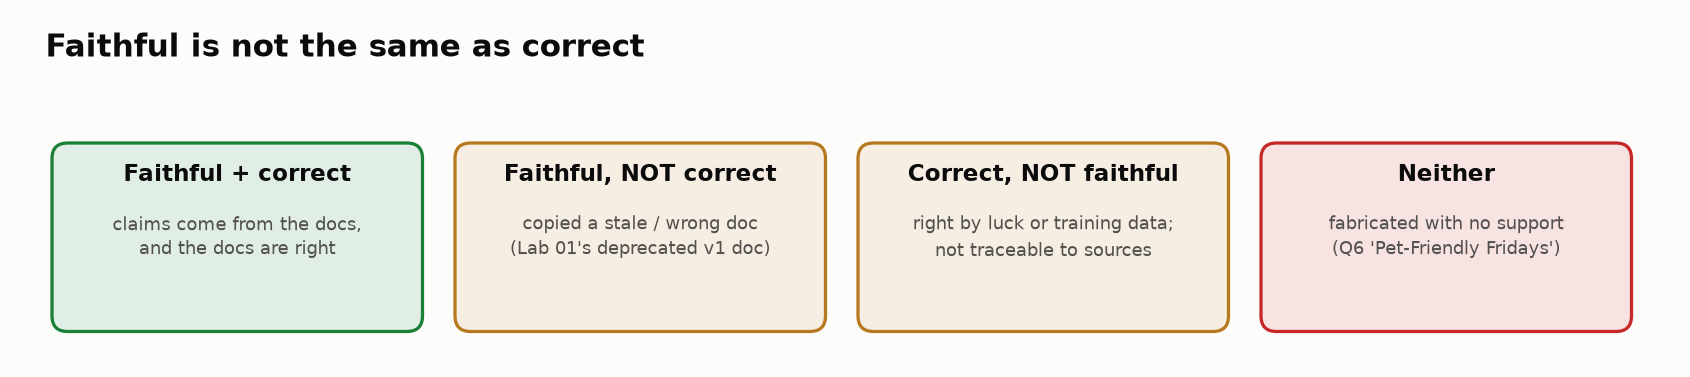

<sub>🖼️ *Grounding/faithfulness and correctness are different axes*</sub>

In [ ]:
# 🧠 YOUR TURN: Define your grounding evaluation criteria below.
# Replace the placeholder entries with your own criteria.
# Add or remove entries as needed (aim for 3-5 criteria).
#
# Think about different types of grounding failures:
#   - Complete fabrication (no source for any claim)
#   - Fact distortion (changing numbers, dates, names from source)
#   - Unsupported additions (adding claims not in any doc)
#   - Partial grounding (some claims supported, others not)

my_grounding_criteria = [
    {
        "name": "...",               # e.g., "claim_attribution" — does each claim trace to a doc?
        "description": "...",        # What does this criterion check?
        "scoring": "...",            # How would you score it? (binary, 1-5 scale, etc.)
        "failure_example": "...",    # What does a failing case look like?
    },
    {
        "name": "...",               # e.g., "numerical_accuracy" — do numbers match the source?
        "description": "...",
        "scoring": "...",
        "failure_example": "...",
    },
    {
        "name": "...",               # e.g., "no_unsupported_claims" — no info beyond the docs?
        "description": "...",
        "scoring": "...",
        "failure_example": "...",
    },
    # Add more criteria if needed
]

# Print your criteria in a readable format
print("📋 My Grounding Evaluation Criteria:\n")
for i, criterion in enumerate(my_grounding_criteria, 1):
    print(f"  {i}. {criterion['name']}")
    print(f"     Description:    {criterion['description']}")
    print(f"     Scoring:        {criterion['scoring']}")
    print(f"     Failure looks like: {criterion['failure_example']}")
    print()

### Checkpoint ✅
After filling in your criteria and running the cell, you should see a formatted printout of your grounding evaluation criteria. Verify that:
- You have at least 3 criteria defined
- Each has a name, description, scoring approach, and failure example
- Your criteria address different types of grounding failures (not just "is it correct?")

> These criteria will inform how you think about the faithfulness scoring in the next task.

Great work designing your rubric! Now let's move from *manual* grounding evaluation to *automated* faithfulness scoring — we'll implement two different approaches and see how they compare.

---

## Task 6: 🧪 Implement Faithfulness Scoring

In the previous task, you designed grounding criteria *manually*. Now we'll build **automated** faithfulness scorers that can evaluate hundreds of responses without human reviewers.

### Goal
Implement two approaches to faithfulness evaluation: a **rule-based method** (keyword/sentence overlap) and an **NLI-based method** (using a cross-encoder to check entailment). Then compare their results.

### 🎯 Why Two Methods?
Each method has different strengths and blind spots:

```
  ┌────────────────────┐         ┌────────────────────┐
  │   Rule-Based       │         │    NLI-Based        │
  │   (Word Overlap)   │         │   (Entailment)      │
  ├────────────────────┤         ├────────────────────┤
  │ ✅ Fast & simple   │         │ ✅ Understands       │
  │ ✅ Interpretable   │         │   meaning/semantics  │
  │ ❌ Misses semantic │         │ ✅ Catches subtle    │
  │   contradictions   │         │   contradictions     │
  │   (12→16 weeks)   │         │ ❌ Slower (needs     │
  │ ❌ Foiled by       │         │   model inference)   │
  │   paraphrases     │         │ ❌ Less transparent   │
  └────────────────────┘         └────────────────────┘
```

> 💡 **Key Insight:** Using multiple evaluation methods helps catch failures that any single method would miss. This is a common pattern in production AI evaluation.

### Background
- **Faithfulness** = does the generated answer only contain claims supported by the retrieved context?
- **NLI (Natural Language Inference)** = given a premise (context) and hypothesis (claim), does the premise *entail* the hypothesis?
- An answer is **faithful** if its claims are entailed by the retrieved documents
- An answer is **unfaithful** if it contains claims not supported by (or contradicted by) the retrieved documents

### Steps
1. Implement a simple rule-based faithfulness scorer using word overlap
2. Load a cross-encoder NLI model for entailment-based scoring
3. Score all 12 queries with both methods
4. Compare the methods

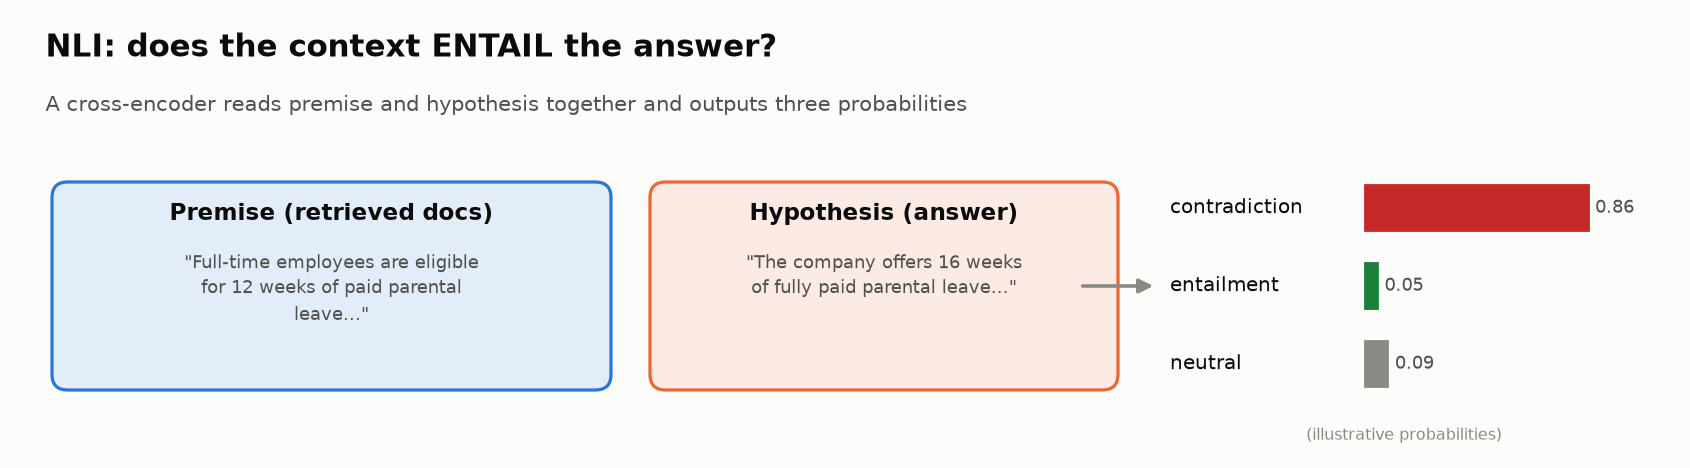

<sub>🖼️ *How an NLI cross-encoder scores one (premise, hypothesis) pair*</sub>

In [ ]:
# ══════════════════════════════════════════════════════════════════
# Method 1: Rule-based faithfulness scoring
# ══════════════════════════════════════════════════════════════════
# Strategy: Check what fraction of CONTENT words in the generated answer
# also appear in the relevant retrieved documents.
#
# Why this works (sometimes): If the answer uses words that never appeared
# in the source docs, it's likely introducing unsupported information.
#
# Why this fails (sometimes): It can't detect when numbers or facts are
# CHANGED — "12 weeks" and "16 weeks" share the word "weeks" so overlap
# looks fine, but the meaning is completely different.
# ══════════════════════════════════════════════════════════════════

import re

def tokenize(text):
    """Simple whitespace + punctuation tokenizer, lowercased.
    Extracts individual words for overlap comparison."""
    return set(re.findall(r'\b\w+\b', text.lower()))

# Common English words that don't carry meaning for faithfulness checking
# We remove these so "the", "is", "a" don't inflate overlap scores
STOP_WORDS = {'the', 'a', 'an', 'is', 'are', 'was', 'were', 'be', 'been', 'being',
              'have', 'has', 'had', 'do', 'does', 'did', 'will', 'would', 'could',
              'should', 'may', 'might', 'shall', 'can', 'to', 'of', 'in', 'for',
              'on', 'with', 'at', 'by', 'from', 'as', 'into', 'through', 'during',
              'and', 'but', 'or', 'nor', 'not', 'so', 'yet', 'both', 'either',
              'neither', 'each', 'every', 'all', 'any', 'few', 'more', 'most',
              'other', 'some', 'such', 'no', 'only', 'own', 'same', 'than',
              'too', 'very', 'just', 'because', 'if', 'when', 'where', 'how',
              'what', 'which', 'who', 'whom', 'this', 'that', 'these', 'those',
              'i', 'me', 'my', 'we', 'our', 'you', 'your', 'he', 'him', 'his',
              'she', 'her', 'it', 'its', 'they', 'them', 'their'}


def rule_based_faithfulness(answer, retrieved_docs, relevance_labels):
    """
    Score faithfulness by measuring what fraction of content words in the answer
    appear in the relevant retrieved documents.

    Returns a score between 0 and 1:
      1.0 = every content word in the answer appears in relevant docs
      0.0 = no overlap (answer is about something completely different)
    """
    # Step 1: Filter to only the RELEVANT documents (using our ground-truth labels)
    relevant_docs = [doc for doc, rel in zip(retrieved_docs, relevance_labels) if rel == 1]

    if not relevant_docs:
        # No relevant docs retrieved — any substantive answer must be fabricated
        answer_words = tokenize(answer) - STOP_WORDS
        if len(answer_words) > 3:  # More than a trivial "I don't know" response
            return 0.0  # Fabrication: answer has content but no source
        return 0.5  # Short/generic response gets neutral score

    # Step 2: Collect all content words from relevant documents
    context_words = set()
    for doc in relevant_docs:
        context_words |= tokenize(doc) - STOP_WORDS

    # Step 3: Check what fraction of answer words appear in context
    answer_words = tokenize(answer) - STOP_WORDS
    if not answer_words:
        return 1.0  # Empty answer can't be unfaithful

    overlap = answer_words & context_words
    return len(overlap) / len(answer_words)  # Overlap ratio


# ── Test on a known faithful example (Query 1: PTO days) ──
item = rag_dataset[0]
score = rule_based_faithfulness(item["generated_answer"], item["retrieved_docs"], item["relevance_labels"])
print(f"Rule-based faithfulness for Query 1 (PTO days): {score:.3f}")
print(f"  (Expected: high score — answer closely mirrors the retrieved doc)\n")

# ── Test on a known unfaithful example (Query 6: pet policy fabrication) ──
item = rag_dataset[5]
score = rule_based_faithfulness(item["generated_answer"], item["retrieved_docs"], item["relevance_labels"])
print(f"Rule-based faithfulness for Query 6 (pet policy): {score:.3f}")
print(f"  (Expected: low score — answer is fabricated with no relevant docs)")
print("\n✅ Rule-based faithfulness scorer ready.")

In [ ]:
# ══════════════════════════════════════════════════════════════════
# Method 2: NLI-based faithfulness scoring
# ══════════════════════════════════════════════════════════════════
# Strategy: Use a pre-trained Natural Language Inference (NLI) model
# to check whether the retrieved context ENTAILS the generated answer.
#
# NLI models classify a (premise, hypothesis) pair into three categories:
#   - ENTAILMENT:    Premise supports/implies the hypothesis    ✅
#   - CONTRADICTION: Premise conflicts with the hypothesis      ❌
#   - NEUTRAL:       Premise neither supports nor contradicts   ⚠️
#
# For faithfulness: premise = relevant docs, hypothesis = generated answer
# High entailment score → answer is supported by the documents
# ══════════════════════════════════════════════════════════════════

from sentence_transformers import CrossEncoder

# Load a lightweight NLI cross-encoder (~90MB download on first run)
# "Cross-encoder" means it processes both texts jointly for better accuracy
nli_model = CrossEncoder("cross-encoder/nli-MiniLM2-L6-H768", max_length=512)
print("✅ NLI cross-encoder loaded: nli-MiniLM2-L6-H768")

# The model outputs scores for three labels
NLI_LABELS = ["contradiction", "entailment", "neutral"]


def nli_faithfulness(answer, retrieved_docs, relevance_labels):
    """
    Score faithfulness using NLI: check if the relevant retrieved documents
    entail the generated answer.

    Concatenates relevant docs as the premise, uses the answer as the hypothesis.
    Returns a dict with:
      - entailment_score: probability that docs support the answer (0-1)
      - contradiction_score: probability that docs contradict the answer (0-1)
      - label: most likely NLI class (entailment/contradiction/neutral)
      - scores: raw probabilities for all three classes
    """
    # Only use relevant documents as the premise
    relevant_docs = [doc for doc, rel in zip(retrieved_docs, relevance_labels) if rel == 1]

    if not relevant_docs:
        # No relevant context — can't assess entailment, return zero
        return {"entailment_score": 0.0, "label": "no_context", "scores": [0, 0, 0]}

    # Concatenate relevant docs into one premise string
    premise = " ".join(relevant_docs)

    # Run the NLI model: does the premise entail the hypothesis (answer)?
    # apply_softmax=True turns the model's raw logits into probabilities that sum to 1.
    # (Without it you get unbounded scores like 3.6 or -2.0 that can't be averaged with 0-1 metrics.)
    scores = nli_model.predict([(premise, answer)], apply_softmax=True)
    scores = scores[0]  # We only have one pair

    predicted_label = NLI_LABELS[np.argmax(scores)]  # Highest-scoring label
    entailment_score = float(scores[1])  # Index 1 = entailment probability

    return {
        "entailment_score": entailment_score,
        "contradiction_score": float(scores[0]),
        "label": predicted_label,
        "scores": [float(s) for s in scores],
    }


# ── Test on the same examples as the rule-based method ──
item = rag_dataset[0]
result = nli_faithfulness(item["generated_answer"], item["retrieved_docs"], item["relevance_labels"])
print(f"\nNLI faithfulness for Query 1 (PTO days):")
print(f"  Entailment score: {result['entailment_score']:.3f}")
print(f"  Predicted label:  {result['label']}")

item = rag_dataset[5]
result = nli_faithfulness(item["generated_answer"], item["retrieved_docs"], item["relevance_labels"])
print(f"\nNLI faithfulness for Query 6 (pet policy):")
print(f"  Entailment score: {result['entailment_score']:.3f}")
print(f"  Predicted label:  {result['label']}")

In [ ]:
# ══════════════════════════════════════════════════════════════════
# Head-to-head comparison: Rule-Based vs NLI across all 12 queries
# ══════════════════════════════════════════════════════════════════
# This is the key comparison — where do the methods agree and disagree?
# Disagreements reveal the strengths and weaknesses of each approach.

comparison = []
for item in rag_dataset:
    rb_score = rule_based_faithfulness(
        item["generated_answer"], item["retrieved_docs"], item["relevance_labels"]
    )
    nli_result = nli_faithfulness(
        item["generated_answer"], item["retrieved_docs"], item["relevance_labels"]
    )
    comparison.append({
        "id": item["id"],
        "query": item["query"][:45] + "...",
        "n_relevant": sum(item["relevance_labels"]),
        "rule_based": rb_score,                          # Word overlap score (0-1)
        "nli_entailment": nli_result["entailment_score"], # Semantic entailment score (0-1)
        "nli_contradiction": nli_result.get("contradiction_score", 0.0), # P(contradiction)
        "nli_label": nli_result["label"],                 # Predicted NLI class
    })

comp_df = pd.DataFrame(comparison)

print("📊 Faithfulness Comparison: Rule-Based vs NLI\n")
print(comp_df.to_string(index=False, float_format="%.3f"))

# Average scores — excluding queries with no context (they'd unfairly lower averages)
print(f"\n--- Method Averages (excluding no-context queries) ---")
has_context = comp_df[comp_df["n_relevant"] > 0]
print(f"  Rule-based mean:     {has_context['rule_based'].mean():.3f}")
print(f"  NLI entailment mean: {has_context['nli_entailment'].mean():.3f}")

### Checkpoint ✅
You should see a comparison table with faithfulness scores from both methods for all 12 queries. All scores are now **probabilities between 0 and 1** (the NLI cell uses `apply_softmax=True`). What you should see:

| Query | Rule-based | NLI entailment | What it shows |
|---|---|---|---|
| 1, 3, 5, 7, 9, 11 | 0.54–0.93 | **≈ 0.93–0.99** | Faithful answers: both methods agree |
| 4, 6 | 0.00 | 0.00 (`no_context`) | No relevant docs, so nothing can support the answer |
| **10** (12 → 16 weeks) | 0.53 (looks OK!) | **0.02**, contradiction 0.25 | Word overlap is fooled by shared vocabulary; NLI is not |
| **8** (credit cards) | 0.82 | **0.04** → `neutral` | ⚠️ A *correct, faithful* answer that the small NLI model can't confirm |
| **2** (client dinners) | 0.64 | 0.31, `contradiction` 0.59 | ⚠️ A false alarm: "client dinner" vs "client entertainment" |

### 🧪 Experiment — Think About This
1. Look at **Query 10**. The rule-based method gives it 0.53 because "weeks", "parental" and "leave" all appear in the source. Why can't word overlap see that 12 became 16?
2. Look at **Queries 8 and 2**. The NLI model *also* makes mistakes: it calls a correct, multi-claim answer "neutral" and flags a reasonable paraphrase as a contradiction. What does that tell you about trusting any single automated evaluator?
3. How might **claim-level** NLI (scoring each sentence separately, Stretch Goal 1) or a larger NLI model change Query 8's result?

> 💡 **Evaluate your evaluator.** Every automated metric has its own failure modes. Checking a scorer on cases where you *know* the right answer, like we just did, is how you learn where to trust it.

### 🔍 What Just Happened?

You built and compared two automated faithfulness scoring methods:

1. **Rule-based** (word overlap): Fast and simple, but can't detect when the LLM *changes* facts while keeping the same vocabulary (like 12→16 weeks).
2. **NLI-based** (entailment): Understands meaning and catches the 12 → 16 weeks distortion, but it has blind spots of its own (Queries 2 and 8) and requires a model.

The key finding: **no single method catches everything**. In production RAG systems, teams often use multiple evaluation signals — just as you did here.

> 🎯 **Why This Matters:** Faithfulness scoring is the core defense against hallucination in RAG systems. A RAG system that sounds confident but makes up facts is worse than one that says "I don't know."

Now that we can measure both retrieval quality AND generation faithfulness, let's see how the system holds up under pressure — time to design **stress tests**.

---

## Task 7: 🧠 Your Turn — Create Stress Test Queries

So far we've evaluated how the RAG system performs on *normal* queries. But production systems face much harder inputs — ambiguous questions, tricky phrasing, and topics outside their scope. Let's design tests that **push the system to its limits**.

### Goal
Design stress test queries that would challenge the RAG system. Good stress tests expose weaknesses that standard queries miss.

### 🎯 Why Stress Test?
Think about Queries 4 and 6 in our dataset — the system retrieved **zero relevant documents** but still generated confident, detailed answers. Now imagine thousands of employees trusting those fabricated answers. Stress tests help you find these dangerous failure modes *before* users do.

> ⚠️ **Common Mistake:** Testing only "happy path" queries gives a false sense of security. The most dangerous failures happen at the edges.

### Context
The company policy RAG system handles questions about PTO, expenses, benefits, safety, and workplace policies. Consider what types of queries would be hardest for this system.

### Categories of Stress Tests

Design **at least 2 queries for each category** below:

1. **Ambiguous queries** — questions with multiple valid interpretations
   - *Example:* "What's the limit?" (Limit of what? PTO? Expenses? Credit card?)

2. **Adversarial queries** — intentionally tricky or misleading phrasing
   - *Example:* "Can I expense my personal vacation if I check email during it?"

3. **Out-of-scope queries** — questions the system shouldn't answer from company policies
   - *Example:* "What is the capital of France?"

4. **Contradictory context queries** — questions where different policies might conflict
   - *Example:* "If I'm on parental leave, does my education stipend deadline get extended?"

### Your Task

In the cell below, create your stress test queries. For each query:
- Write the query text
- Identify the category
- Explain **what failure mode** you expect it to trigger
- Describe what a **good** vs **bad** response would look like

**Hint:** Think about what happened with Queries 4 and 6 in our dataset — the system retrieved zero relevant docs but still generated confident answers. What kinds of queries would maximize that risk?

> ⚠️ There is no single correct answer set. Design queries that *you* think would expose real weaknesses.

In [ ]:
# 🧠 YOUR TURN: Design stress test queries for the RAG system.
# Replace the placeholders with your own queries.
# Aim for at least 2 queries per category (8+ total).
#
# Tips for effective stress tests:
#   - Ambiguous: use vague pronouns, omit key context
#   - Adversarial: phrase things to trick the system into incorrect answers
#   - Out-of-scope: ask about topics with no policy document
#   - Contradictory: combine two policies that might clash

my_stress_tests = [
    # --- Ambiguous Queries ---
    # These test whether the system asks for clarification or guesses
    {
        "query": "...",
        "category": "ambiguous",
        "expected_failure": "...",       # What failure mode should this trigger?
        "good_response": "...",          # What would a good response look like?
        "bad_response": "...",           # What would a bad response look like?
    },
    {
        "query": "...",
        "category": "ambiguous",
        "expected_failure": "...",
        "good_response": "...",
        "bad_response": "...",
    },

    # --- Adversarial Queries ---
    # These test whether the system can resist leading/misleading questions
    {
        "query": "...",
        "category": "adversarial",
        "expected_failure": "...",
        "good_response": "...",
        "bad_response": "...",
    },
    {
        "query": "...",
        "category": "adversarial",
        "expected_failure": "...",
        "good_response": "...",
        "bad_response": "...",
    },

    # --- Out-of-Scope Queries ---
    # These test whether the system knows its own boundaries
    {
        "query": "...",
        "category": "out_of_scope",
        "expected_failure": "...",
        "good_response": "...",
        "bad_response": "...",
    },
    {
        "query": "...",
        "category": "out_of_scope",
        "expected_failure": "...",
        "good_response": "...",
        "bad_response": "...",
    },

    # --- Contradictory Context Queries ---
    # These test whether the system handles mixed signals from different policies
    {
        "query": "...",
        "category": "contradictory_context",
        "expected_failure": "...",
        "good_response": "...",
        "bad_response": "...",
    },
    {
        "query": "...",
        "category": "contradictory_context",
        "expected_failure": "...",
        "good_response": "...",
        "bad_response": "...",
    },
]

# Print your stress tests in a readable format
print(f"📋 My Stress Test Suite: {len(my_stress_tests)} queries\n")
for i, test in enumerate(my_stress_tests, 1):
    print(f"  {i}. [{test['category'].upper()}] \"{test['query']}\"")
    print(f"     Expected failure: {test['expected_failure']}")
    print()

# Summary by category — verify you have good coverage
from collections import Counter
cat_counts = Counter(t["category"] for t in my_stress_tests)
print("Category distribution:")
for cat, count in cat_counts.items():
    print(f"  {cat}: {count}")

### Checkpoint ✅
After filling in your stress tests and running the cell, verify that:
- You have at least 8 stress test queries total
- Each category has at least 2 queries
- Each query has a clear expected failure mode
- Your queries are specific enough to test concrete weaknesses (not just "a hard question")

> We'll discuss stress test design patterns as a group.

### 🔍 What Just Happened?

You designed a suite of stress test queries across four categories — ambiguous, adversarial, out-of-scope, and contradictory. Each type targets a different failure mode:

| Category | What It Tests | Danger If Not Caught |
|----------|--------------|---------------------|
| Ambiguous | Can the system handle vague input? | Answers wrong interpretation confidently |
| Adversarial | Can the system resist tricks? | Produces incorrect policy guidance |
| Out-of-scope | Does it know its limits? | Fabricates answers it shouldn't give |
| Contradictory | Can it handle conflicting policies? | Gives misleading advice on edge cases |

Stress testing is how you find the failure modes that *normal* queries miss. In the final task, we'll tie everything together by **tracing** each query through the full pipeline to pinpoint exactly where failures occur.

---

## Task 8: 🔬 Analyze Traced RAG Examples

We now have retrieval metrics (Task 4) and faithfulness scores (Task 6). In this task, we **combine everything** into a full pipeline trace — examining each query's journey from start to finish.

### Goal
Examine the full RAG pipeline trace for each query: **query → retrieval → generation**. For each query, determine whether the failure (if any) originated in the **retrieval step** or the **generation step**.

### 🎯 Why Tracing Matters

```
  Without tracing:              With tracing:
  ────────────────              ────────────────
  "The answer is wrong"    →    "Retrieval failed → no relevant docs
   🤷 Fix what?                  → LLM hallucinated an answer
                                  → Fix: improve retriever first"
```

In production RAG systems, you can't fix what you can't diagnose. If the answer is wrong:
- Was it because retrieval returned irrelevant documents? → Fix the retriever (embeddings, chunking, index)
- Was it because generation ignored or distorted the context? → Fix the prompt, model, or guardrails
- Was it both? → Prioritize the upstream problem (retrieval) first

> 💡 **Key Insight:** Tools like LangSmith and Langfuse provide this tracing automatically in production. Here we're building a simplified version to understand the concept.

### Steps
Run the cells below to build a trace analysis for each query and classify failures.

In [ ]:
# ══════════════════════════════════════════════════════════════════
# Build a full trace analysis for each query in the dataset
# This simulates what a trace tool (like Langfuse/LangSmith) would show:
#   - How did retrieval perform?
#   - How did generation perform?
#   - Where is the root cause of any failure?
# ══════════════════════════════════════════════════════════════════

def analyze_trace(item, rb_score, nli_score):
    """
    Analyze a single RAG trace and classify the failure mode.

    Takes the raw data (item), rule-based faithfulness score, and NLI score.
    Returns a dict with retrieval status, generation status, and root cause.
    """
    retrieval_quality = sum(item["relevance_labels"]) / len(item["relevance_labels"])
    n_relevant = sum(item["relevance_labels"])

    # ── Step 1: Classify RETRIEVAL quality ──
    if n_relevant == 0:
        retrieval_status = "❌ FAILURE"
        retrieval_diagnosis = "No relevant documents retrieved"
    elif n_relevant <= 1:
        retrieval_status = "⚠️ WEAK"
        retrieval_diagnosis = f"Only {n_relevant}/5 relevant doc(s) — limited context"
    else:
        retrieval_status = "✅ GOOD"
        retrieval_diagnosis = f"{n_relevant}/5 relevant docs retrieved"

    # ── Step 2: Classify GENERATION quality ──
    # Combine both faithfulness signals for a more robust assessment
    avg_faithfulness = (rb_score + nli_score) / 2

    # Also check against ground truth with simple word overlap
    gt_words = tokenize(item["ground_truth"]) - STOP_WORDS
    ans_words = tokenize(item["generated_answer"]) - STOP_WORDS
    gt_overlap = len(gt_words & ans_words) / len(gt_words) if gt_words else 1.0

    if avg_faithfulness >= 0.6 and gt_overlap >= 0.4:
        generation_status = "✅ GOOD"
        generation_diagnosis = "Answer is faithful to context and matches ground truth"
    elif n_relevant == 0 and len(ans_words) > 5:
        generation_status = "❌ HALLUCINATION"
        generation_diagnosis = "Generated substantive answer without relevant context"
    elif avg_faithfulness < 0.4:
        generation_status = "❌ UNFAITHFUL"
        generation_diagnosis = "Answer contains claims not supported by retrieved docs"
    else:
        generation_status = "⚠️ PARTIAL"
        generation_diagnosis = "Answer partially supported — some claims may be unsupported"

    # ── Step 3: Determine ROOT CAUSE ──
    # This is the actionable insight: where should engineers focus?
    if "FAILURE" in retrieval_status and "HALLUCINATION" in generation_status:
        root_cause = "RETRIEVAL → led to HALLUCINATION"
    elif "GOOD" in retrieval_status and "UNFAITHFUL" in generation_status:
        root_cause = "GENERATION — good docs but unfaithful answer"
    elif "GOOD" in retrieval_status and "GOOD" in generation_status:
        root_cause = "NO FAILURE — system worked correctly"
    elif "FAILURE" in retrieval_status:
        root_cause = "RETRIEVAL — no relevant docs found"
    else:
        root_cause = "MIXED — partial retrieval and/or generation issues"

    return {
        "id": item["id"],
        "query": item["query"],
        "retrieval_status": retrieval_status,
        "retrieval_diagnosis": retrieval_diagnosis,
        "generation_status": generation_status,
        "generation_diagnosis": generation_diagnosis,
        "root_cause": root_cause,
        "faithfulness_rb": rb_score,
        "faithfulness_nli": nli_score,
        "gt_overlap": gt_overlap,
    }

# ── Run trace analysis for all 12 queries ──
traces = []
for item in rag_dataset:
    rb = rule_based_faithfulness(item["generated_answer"], item["retrieved_docs"], item["relevance_labels"])
    nli = nli_faithfulness(item["generated_answer"], item["retrieved_docs"], item["relevance_labels"])
    trace = analyze_trace(item, rb, nli["entailment_score"])
    traces.append(trace)

print("✅ Trace analysis complete for all 12 queries.")

In [ ]:
# ── Display detailed trace analysis for each query ──
# This is the "trace view" — showing the full pipeline status for each query
# In production, tools like Langfuse/LangSmith generate this automatically

print("=" * 80)
print("📋 RAG PIPELINE TRACE ANALYSIS")
print("=" * 80)

for trace in traces:
    print(f"\n📋 Query {trace['id']}: \"{trace['query']}\"")
    print(f"   ┌─ RETRIEVAL: {trace['retrieval_status']}")
    print(f"   │  {trace['retrieval_diagnosis']}")
    print(f"   │")
    print(f"   ├─ GENERATION: {trace['generation_status']}")
    print(f"   │  {trace['generation_diagnosis']}")
    print(f"   │  Faithfulness (rule-based): {trace['faithfulness_rb']:.3f}")
    print(f"   │  Faithfulness (NLI):        {trace['faithfulness_nli']:.3f}")
    print(f"   │  Ground truth overlap:      {trace['gt_overlap']:.3f}")
    print(f"   │")
    print(f"   └─ ROOT CAUSE: {trace['root_cause']}")
    print(f"   {'─' * 60}")

In [ ]:
# ── Summary: group all queries by their root cause ──
# This is the "executive dashboard" view — what categories of failures exist?
print("\n📊 Root Cause Summary\n")
root_cause_counts = defaultdict(list)
for trace in traces:
    root_cause_counts[trace["root_cause"]].append(trace["id"])

for cause, ids in root_cause_counts.items():
    print(f"  {cause}")
    print(f"    Queries: {ids}")
    print()

# ── The most actionable insight from trace analysis ──
print("=" * 60)
print("🎯 KEY INSIGHT")
print("=" * 60)
print("""
RAG failures have different root causes that require different fixes:

  • Retrieval failures → improve embeddings, chunking, or index coverage
  • Generation failures → improve prompts, add guardrails, or switch models
  • Mixed failures → fix retrieval first (upstream), then evaluate generation

Trace analysis tells you WHERE to invest engineering effort.
Without it, you're guessing.
""")

### Checkpoint ✅
You should see a detailed trace analysis for all 12 queries, showing:
- Retrieval status (✅ GOOD, ⚠️ WEAK, ❌ FAILURE) for each
- Generation status (✅ GOOD, ⚠️ PARTIAL, ❌ HALLUCINATION, ❌ UNFAITHFUL)
- Faithfulness scores from both methods
- Root cause classification

Key queries to examine:
- **Query 4** (PTO balance exceeded): Retrieval failure → hallucination. Zero relevant docs, but a confident fabricated answer.
- **Query 6** (pets in office): Same pattern — retrieval failure leading to complete fabrication.
- **Query 10** (parental leave): This is the subtle one — retrieval is good (4/5 relevant), but generation distorts a key fact (12→16 weeks).
- **Queries 5, 9, 11**: No failure: good retrieval, faithful generation.
- **Query 8** (credit cards): Perfect retrieval, but generation is marked ⚠️ PARTIAL only because the NLI model said "neutral". This is an **evaluator** error, not a system error. Spotting that is part of the job.
- **Queries 1, 3, 7** show as MIXED because only 1 of 5 retrieved docs was relevant (low precision), even though their answers are good.

### 🔍 What Just Happened?

You just built a full **end-to-end trace analysis** for every query in the dataset. For each query, you now know:
- Whether the **retriever** succeeded or failed
- Whether the **generator** was faithful or hallucinated
- The **root cause** of any failure (retrieval, generation, or both)

This is the foundation of production RAG monitoring. Instead of just knowing "the answer was wrong," you can now say *why* it was wrong and *what to fix*.

The most dangerous pattern you found: **retrieval failure + confident generation** (Queries 4 and 6). The system had zero evidence but still produced detailed, authoritative-sounding answers. This is the RAG failure mode that costs companies real money and trust.

In the final challenge, you'll investigate the subtle cases where retrieval and generation quality *diverge*.

---

## Task 9: ⚠️ Open Challenge — Retrieval-Generation Failure Analysis

This is the capstone analysis. You've measured retrieval, scored faithfulness, and traced failures. Now put it all together to find the **most dangerous** failure pattern: when one component succeeds but the other fails.

### Goal
Using the trace analysis above, find and document specific cases of **retrieval-generation divergence**: situations where one component succeeds but the other fails. This is the most dangerous class of RAG failure because it's invisible to simple end-to-end metrics.

### 🎯 Why This Is the Hardest Problem

```
           Retrieval    Generation    Visible to User?    Danger Level
           ─────────    ──────────    ────────────────    ────────────
  Case 1:    ✅ Good      ✅ Good     Answer correct       ✅ Safe
  Case 2:    ❌ Bad       ❌ Bad      Answer clearly wrong  ⚠️ Moderate
  Case 3:    ✅ Good      ❌ Bad      Answer sounds right   🔴 HIGH
  Case 4:    ❌ Bad       ✅ "Good"   Answer sounds right   🔴 HIGHEST
```

> 💡 **Key Insight:** Cases 3 and 4 are the most dangerous because users can't tell something is wrong. The answer sounds authoritative, but it's either distorted (Case 3) or fabricated (Case 4).

### The Challenge

Find examples in the dataset (or reason about hypothetical cases) for BOTH of these patterns:

### Pattern A: Retrieval Succeeds, Generation Fails
The system retrieves the right documents, but the generated answer is wrong, incomplete, or distorted.

- Which query (or queries) in the dataset match this pattern?
- What specifically went wrong in the generation step?
- How would you detect this automatically in production?
- What would you change to fix it?

### Pattern B: Retrieval Fails, Generation "Succeeds"
The system retrieves irrelevant documents, but produces a plausible-sounding answer anyway.

- Which query (or queries) in the dataset match this pattern?
- Why is this pattern **more dangerous** than a query where both retrieval and generation fail?
- How would the end user experience differ from Pattern A?
- What guardrail could prevent this?

### Your Task

In the cells below:
1. Identify specific queries matching each pattern
2. Explain the root cause
3. Propose a detection strategy and fix

> There are multiple valid analyses. The goal is to think critically about how retrieval and generation quality interact — and why evaluating them separately is essential.

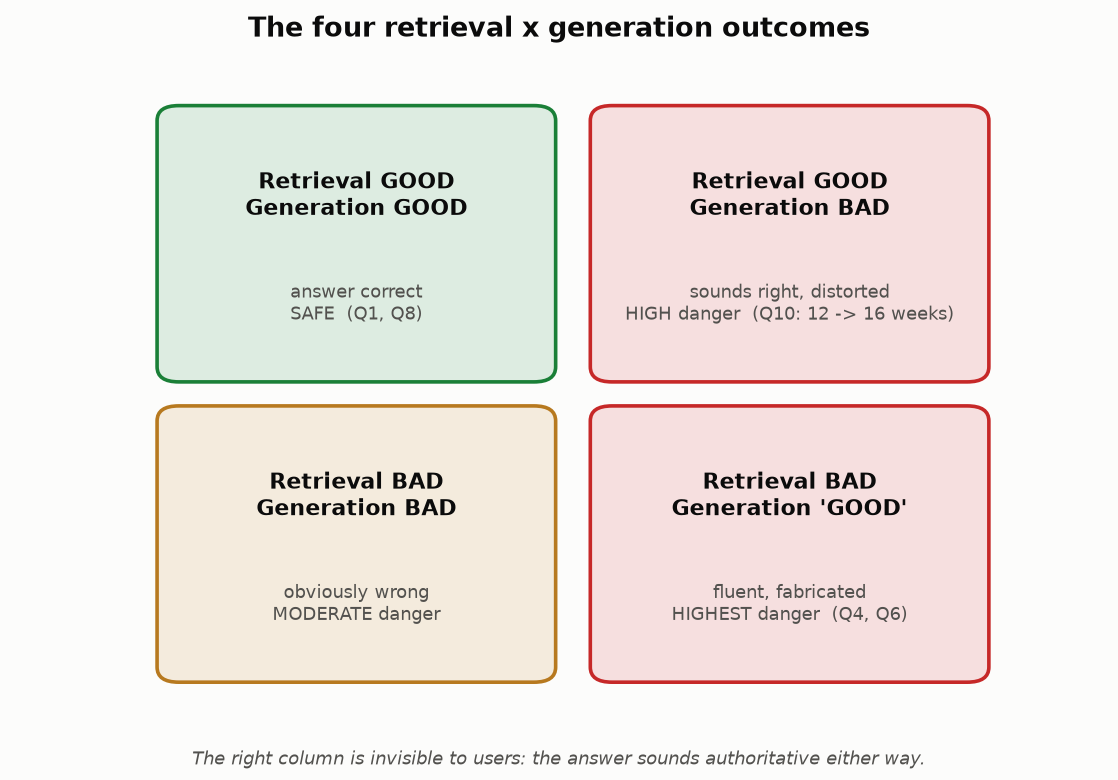

<sub>🖼️ *The four retrieval × generation outcomes, with this dataset's examples*</sub>

In [ ]:
# ── Helper: Deep-dive into a specific query to support your analysis ──
# Use this to inspect any query in detail — change the query_id to explore different cases
# This shows the full pipeline: query → retrieved docs → generated answer → ground truth → trace

def inspect_query(query_id):
    """Print full details of a specific query for analysis."""
    item = rag_dataset[query_id - 1]   # Convert 1-based ID to 0-based index
    trace = traces[query_id - 1]

    print(f"{'=' * 70}")
    print(f"🔬 DEEP DIVE: Query {item['id']}")
    print(f"{'=' * 70}")
    print(f"\nQuery: \"{item['query']}\"")
    print(f"\n--- Retrieved Documents (what the retriever gave the LLM) ---")
    for i, (doc, rel) in enumerate(zip(item["retrieved_docs"], item["relevance_labels"])):
        status = "✅ RELEVANT" if rel == 1 else "❌ NOT RELEVANT"
        print(f"  Doc {i+1} [{status}]: \"{doc[:100]}...\"")
    print(f"\n--- Generated Answer (what the LLM produced) ---")
    print(f"  \"{item['generated_answer']}\"")
    print(f"\n--- Ground Truth (the correct answer) ---")
    print(f"  \"{item['ground_truth']}\"")
    print(f"\n--- Trace Analysis (our evaluation) ---")
    print(f"  Retrieval:  {trace['retrieval_status']} — {trace['retrieval_diagnosis']}")
    print(f"  Generation: {trace['generation_status']} — {trace['generation_diagnosis']}")
    print(f"  Root cause: {trace['root_cause']}")
    print(f"{'=' * 70}")

# ── Inspect key queries for your analysis ──
# Query 10: Parental leave — retrieval is great, but generation distorts "12 weeks" → "16 weeks"
inspect_query(10)  # Potential Pattern A (good retrieval, bad generation)
print()
# Query 4: PTO balance — zero relevant docs, but confident fabricated answer
inspect_query(4)   # Potential Pattern B (bad retrieval, "good" generation)

# 💡 Try other queries too! Call inspect_query(6) for pets, inspect_query(8) for credit cards, etc.

### ✍️ Your Analysis

**Write your findings here** (double-click to edit):

### Pattern A: Retrieval Succeeds, Generation Fails

**Query ID(s):** *...*

**What went wrong in generation?**

*Your answer...*

**How would you detect this automatically?**

*Your answer...*

**Proposed fix:**

*Your answer...*

---

### Pattern B: Retrieval Fails, Generation "Succeeds"

**Query ID(s):** *...*

**Why is this more dangerous?**

*Your answer...*

**How does the end user experience differ?**

*Your answer...*

**Proposed guardrail:**

*Your answer...*

---

## ✅ Validation / Success Criteria

You have completed this lab successfully if:

- [x] 📊 RAG evaluation dataset loaded and explored (12 queries with retrieved docs and relevance labels)
- [x] 🤔 Completed the 🔍 Think First reflection on what makes RAG responses trustworthy
- [x] 📏 Retrieval metrics computed for all queries (Recall@K, Precision@K, nDCG)
- [x] 📝 Designed 3+ grounding evaluation criteria in the 🧠 Your Turn challenge
- [x] 🧪 Faithfulness scored with both rule-based and NLI methods
- [x] 💥 Designed 8+ stress test queries across 4 categories in the 🧠 Your Turn challenge
- [x] 🔬 Trace analysis completed — root causes identified for all queries
- [x] ⚠️ Completed the Open Challenge — identified retrieval-generation divergence patterns

---

## 🛠️ Troubleshooting

| Symptom | Likely Cause | Fix |
|---------|-------------|-----|
| `ModuleNotFoundError: sentence_transformers` | Package not installed | Re-run the `pip install` cell and restart kernel |
| NLI model download hangs or fails | Network issue in Colab | Try restarting runtime; model is ~90MB and may take 1-2 min |
| `RuntimeError` on NLI model loading | CUDA/GPU issue | The model works on CPU by default; if issues persist, restart the runtime |
| Retrieval metrics all show 0 | Wrong data format | Check that `relevance_labels` is a list of 0s and 1s matching `retrieved_docs` |
| Rule-based faithfulness scores seem too high | Stop word filtering | The rule-based method uses word overlap — it can't detect semantic contradictions (e.g., 12→16 weeks) |
| NLI scores are unexpected | Context length truncation | The cross-encoder truncates inputs at 512 tokens — long doc concatenations may lose information |
| `ZeroDivisionError` in metrics | Division by zero when no relevant docs | The functions handle this — check you're using the provided metric functions |

---

## 🚀 Stretch Goal / Extension

If you finish early, try one or more of these:

1. **Claim-level faithfulness:** Instead of scoring the entire answer at once, split the generated answer into individual claims (sentences) and score each claim separately against the context. Which claims are supported? Which are fabricated?

2. **Retrieval at different K values:** Compute Recall@3 and Precision@3 alongside Recall@5 and Precision@5. How do the metrics change? What does this tell you about the retrieval component?

3. **Build an automated grounding checker:** Using the grounding criteria you designed in Task 5, implement a function that takes a generated answer and retrieved docs and returns a grounding score. Test it on the dataset.

4. **Simulate a guardrail:** Write a function that checks if retrieval quality is too low (e.g., Recall@5 < 0.2) and blocks the system from generating an answer — returning "I don't have enough information to answer this" instead. Which queries would this catch?

---

## 🎯 Key Takeaways

1. 🔀 **Evaluate retrieval and generation separately.** Aggregate end-to-end metrics hide whether the problem is in finding the right documents or in using them correctly.

2. 📏 **Retrieval metrics (Recall, Precision, nDCG) measure different things.** Recall asks "did we find the right docs?" Precision asks "how much noise?" nDCG asks "are the best docs ranked first?"

3. ⚖️ **Faithfulness ≠ correctness.** An answer can be faithful to the retrieved context but still wrong (if retrieval failed). An answer can be correct despite unfaithful generation (if the model "knew" the answer from training data).

4. 🚨 **The most dangerous RAG failure is retrieval failure + confident generation.** The system produces a plausible-sounding answer with zero supporting evidence. This is invisible to users and requires separate evaluation.

5. 💥 **Stress tests expose weaknesses that normal queries miss.** Ambiguous, adversarial, and out-of-scope queries reveal how the system behaves at its boundaries.

6. 🔬 **Trace analysis tells you WHERE to invest effort.** Without traces, you know the answer is wrong but not why. With traces, you can attribute failures to specific pipeline stages and fix them efficiently.

---

## 👀 What's Next?

In **Module 05: Evaluating Generative Outputs**, you'll shift focus from the RAG pipeline to the **generation quality** itself. You'll learn to evaluate:
- **Fluency, coherence, and relevance** of generated text
- **Automated scoring** with metrics like ROUGE, BERTScore, and G-Eval
- **Human evaluation frameworks** and inter-annotator agreement
- **LLM-as-judge** approaches for scalable evaluation

The faithfulness scoring techniques you built in this module will connect directly to Module 05's coverage of generation quality metrics — you'll see how retrieval evaluation and generation evaluation work together as a complete system.

---

## 🏋️ Exercises

Practice RAG evaluation: retrieval metrics, grounding, and faithfulness.

### Exercise 1 — Beginner: Precision@k
Compute precision@k from retrieved doc **ids** (the form you'll use in Lab 04b), given retrieved doc ids and a set of relevant ids.

<details>
<summary>Show solution</summary>

```python
def precision_at_k_ids(retrieved, relevant, k):
    top = retrieved[:k]
    return sum(d in relevant for d in top) / k
print(precision_at_k_ids(["d1","d2","d3"], {"d1","d3"}, 3))
```
</details>

### Exercise 2 — Applied: Recall@k
Compute recall@k for the same inputs.

<details>
<summary>Show solution</summary>

```python
def recall_at_k_ids(retrieved, relevant, k):
    top = set(retrieved[:k])
    return len(top & relevant) / len(relevant)
print(recall_at_k_ids(["d1","d2","d3"], {"d1","d3"}, 3))
```
</details>

### Exercise 3 — Challenge: Grounding check
Flag an answer as ungrounded if none of its sentences overlap the retrieved context.

<details>
<summary>Show solution</summary>

```python
def is_grounded(answer, context, min_overlap=2):
    ctx = set(context.lower().split())
    return any(len(set(s.lower().split()) & ctx) >= min_overlap for s in answer.split("."))
print(is_grounded("The limit is 50 MB.", "max upload limit is 50 MB"))
```
</details>

### Exercise 4 — Stretch: Stress test retrieval
Add 3 noisy/distractor documents and re-measure precision/recall. Did retrieval degrade? (Open-ended.)
